# 15 — LSA passo per passo (versione didattica)

Questo notebook segue **una sola riga** di Multi-News (un cluster di 2-3 articoli + il riassunto
umano di riferimento) e mostra, un passaggio alla volta, come **LSA — Latent Semantic Analysis**
(Gong & Liu, 2001; Steinberger & Ježek, 2004) trasforma il testo in un riassunto estrattivo e come lo si valuta.

A differenza di [`notebooks/15_lsa.ipynb`](../notebooks/15_lsa.ipynb), che gira in batch su
migliaia di righe e salva solo i risultati, qui l'obiettivo è **capire**: ogni passaggio è spiegato,
calcolato "a mano" quando possibile (la SVD con `numpy`, la salienza, la deflazione) e **verificato
contro l'implementazione del benchmark** (le `assert` garantiscono che quello che vedi qui sia
esattamente ciò che fa il codice di produzione).

## Il workflow in una figura

```
documento (2-3 articoli)
      │  1. scelta della riga
      ▼
frasi  s₀ s₁ … s_{N-1}            ← 2. suddivisione in frasi
      │
      ▼
matrice A frase × termine           ← 3. pesi TF-IDF
      │
      ▼
A = U · Σ · Vᵀ                      ← 4. SVD: concetti latenti (σ = importanza, Vᵀ = parole del concetto)
      │  troncata a k concetti
      ▼
Z = U_k · Σ_k  (frase × concetto)   ← 5. ogni frase diventa un vettore corto; salienza = ‖z‖
      │
      ├──► 6. (a parte) similarità nello spazio dei concetti: la "sinonimia"
      ▼
selezione                           ← 7. lsa: top-k per ‖z‖  |  lsa_steinberger: greedy con deflazione
      │
      ▼
riassunto estrattivo                ← 8-9. selezione + generazione (frasi in ordine di documento)
      │
      ▼
confronto con il riferimento        ← 10. + variante a budget di parole
      │
      ▼
ROUGE / BLEU / METEOR               ← 11. metriche
      │
      ▼
interpretazione                     ← 12-13.
```

## L'idea in due righe
Si costruisce la matrice **frase × termine** e la si scompone con la **SVD** in poche direzioni
("concetti") ordinate per importanza: i primi concetti sono i temi ricorrenti del cluster, gli ultimi
rumore. Una frase è **importante** se ha un vettore **lungo** nello spazio dei concetti, cioè se porta
*molto* contenuto sui concetti *importanti*:

> salienza(frase i) = ‖zᵢ‖ = √( Σₖ σₖ² · uᵢₖ² )

Il benchmark ne genera **due varianti** dalla stessa SVD, che differiscono solo per la regola di selezione:

- **`lsa`** — le frasi con salienza più alta (*top-k*, come `sumy.LsaSummarizer`): nessuna memoria di
  cosa è già stato scelto;
- **`lsa_steinberger`** — *greedy con deflazione*: dopo ogni scelta si **sottrae** dallo spazio la
  direzione appena coperta, così le frasi che ripetono la prima perdono valore. È l'**anti-ridondanza**
  della variante multi-documento di Steinberger.

> Come Centroid+MMR ([`11`](11_centroid_mmr_didattico.ipynb)) e a differenza di TextRank/LexRank
> ([`01`](01_textrank_didattico.ipynb), [`02`](02_lexrank_didattico.ipynb)) qui non c'è grafo né PageRank:
> c'è una fattorizzazione di matrici. I passi 1-3 e 10-12 sono identici agli altri notebook didattici.

⚠️ **Una riga non è un benchmark.** Le metriche della sezione 11 riguardano un solo esempio e
servono a capire *come si calcolano*, non a stabilire quale metodo sia migliore (per questo
esistono i notebook di benchmark su 5.610 righe).

## 0. Preparazione
Importiamo le librerie e le funzioni condivise del progetto (`summ_utils`). Il notebook si può
lanciare dalla cartella `notebooks_didattici/` o dalla radice del repository. Gira tutto su CPU,
senza modelli da scaricare.

In [1]:
import sys
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# radice del progetto: la cartella sopra notebooks_didattici/ (o la cwd se già alla radice)
_cwd = Path.cwd()
BASE = _cwd.parent if _cwd.name in ('notebooks_didattici', 'notebooks') else _cwd
sys.path.insert(0, str(BASE / 'notebooks'))

import summ_utils as su
from pyAutoSummarizer.base import psr

su.stile_grafici()
pd.set_option('display.max_colwidth', 110)
pd.set_option('display.width', 200)
plt.rcParams['figure.dpi'] = 110

P = su.percorsi_standard(BASE)
print('Radice del progetto:', BASE)

C:\Users\maccu\AppData\Roaming\Python\Python312\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.5.0) or chardet (7.6.0)/charset_normalizer (3.4.7) doesn't match a supported version!
  warnings.warn(


C:\Users\maccu\AppData\Roaming\Python\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Radice del progetto: C:\Users\maccu\OneDrive\Desktop\Master_Project


## 1. Selezione del testo di partenza
Multi-News è composto da *cluster*: ogni riga contiene **2-3 articoli** sullo stesso evento,
concatenati con il separatore `|||||`, e un **riassunto scritto da un umano** (il
*riferimento*, o *gold*). Lavoriamo sulla **split di test** (la stessa su cui il benchmark
valuta i metodi).

`ROW_ID` è l'indice globale della riga in `data/tab/complete.tab`. La riga predefinita
(**50492**) è stata scelta perché è breve (19 frasi): matrici e grafici restano **leggibili**.
Puoi cambiare `ROW_ID` con qualunque altra riga della split di test (50491-56100): il resto del
notebook si adatta (con documenti molto lunghi i grafici diventano però fitti).

**`MODALITA`** sceglie come viene fissata la **lunghezza** del riassunto. LSA produce un
*ordine* delle frasi (per salienza, o la sequenza del greedy): quante frasi prenderne è una scelta esterna.

| `MODALITA` | regola | corrisponde a |
|---|---|---|
| `'frasi'` | le prime `N_SENTENCES` (= 11) frasi dell'ordine | ambito `test` del benchmark |
| `'budget'` | frasi nell'ordine finché si raggiunge la lunghezza in parole del riferimento, poi tetto a 1,25× | ambito `test_budgetref` (issue #16) |

Cambiando `MODALITA` le sezioni 8-12 si adattano; le due alternative restano comunque
confrontabili nelle tabelle delle sezioni 10 e 11.

**`VARIANTE`** sceglie la regola di selezione: `'lsa_steinberger'` (greedy con deflazione, default) oppure
`'lsa'` (top-k). La sezione 7 le mostra entrambe, la 13 le confronta sulla stessa riga.
`K_LATENTE` è il numero di concetti tenuti dalla SVD (11 nel benchmark, anche nell'ambito a budget: è
un parametro **strutturale**, non di lunghezza).

In [2]:
ROW_ID = 50492          # riga della split di test (50491-56100)
# Come si decide la LUNGHEZZA del riassunto (LSA produce solo un ordine delle frasi):
#   'frasi'  -> le prime N_SENTENCES frasi dell'ordine (benchmark ambito `test`)
#   'budget' -> frasi nell'ordine fino alla lunghezza in parole del riferimento,
#               poi tetto a 1,25x (benchmark ambito `test_budgetref`, issue #16)
MODALITA = 'budget'
N_SENTENCES = 11                  # usato se MODALITA == 'frasi' (mediana del corpus)
VARIANTE = 'lsa_steinberger'      # 'lsa' (top-k per ||z||) | 'lsa_steinberger' (greedy con deflazione)
K_LATENTE = N_SENTENCES           # concetti tenuti dalla SVD (come il benchmark: 11)
K_ORDINE_BUDGET = 50              # lunghezza massima dell'ordine in modalità 'budget' (come il benchmark)
SEED = 42                         # random_state di TruncatedSVD (come il benchmark)
assert MODALITA in ('frasi', 'budget'), "MODALITA deve essere 'frasi' oppure 'budget'"
assert VARIANTE in ('lsa', 'lsa_steinberger'), "VARIANTE deve essere 'lsa' oppure 'lsa_steinberger'"

import csv

PRIMO_ROW_ID_TEST = 50491          # le righe di test sono 50491-56100 in complete.tab
PERCORSO_TEST = P['complete_tab'].with_name('test.tab')   # solo split test (68 MB): basta e avanza

def carica_riga_test(row_id):
    """Legge UNA riga di test. Prima da data/tab/test.tab (leggero, ideale su Colab: row_id = 50491 + indice,
    allineamento verificato con complete.tab), altrimenti da complete.tab (690 MB)."""
    problemi = []
    if PERCORSO_TEST.exists():
        try:
            with open(PERCORSO_TEST, encoding='utf-8', newline='') as f:
                lettore = csv.reader(f, delimiter='\t')
                for _ in range(su.HEADER_LINES_TAB):
                    next(lettore)
                for i, riga in enumerate(lettore):
                    if i == row_id - PRIMO_ROW_ID_TEST:
                        documento, riassunto_umano = riga          # ValueError se la riga è corrotta
                        return {'row_id': row_id, 'split': 'test', 'document': documento, 'summary': riassunto_umano}
            problemi.append(f'{PERCORSO_TEST.name}: row_id {row_id} fuori dalla split di test (50491-56100)')
        except ValueError:
            problemi.append(f'{PERCORSO_TEST.name} è incompleto o corrotto (riga con un numero di colonne inatteso)')
    else:
        problemi.append(f'{PERCORSO_TEST} non trovato')
    if P['complete_tab'].exists():
        try:
            return next(es for es in su.itera_split(P['complete_tab'], 'test') if es['row_id'] == row_id)
        except (ValueError, StopIteration):
            problemi.append(f'{P["complete_tab"].name} è incompleto o corrotto')
    else:
        problemi.append(f'{P["complete_tab"]} non trovato')
    raise RuntimeError('Impossibile leggere la riga: ' + ' | '.join(problemi) + '.\n'
        'I file .tab del repository sono su Git LFS: un `git clone` senza LFS (o un upload interrotto su Colab) '
        'dà un puntatore di pochi byte o un file troncato. Soluzioni: `git lfs pull`, oppure carica '
        'data/tab/test.tab (68 MB) in <radice>/data/tab/.')

esempio = carica_riga_test(ROW_ID)

articoli = [a.strip() for a in esempio['document'].split('|||||')]
riferimento = su.pulisci_riferimento(esempio['summary'])

print(f"row_id {ROW_ID} | split: {esempio['split']} | articoli nel cluster: {len(articoli)}")
print(f"parole nel documento: {len(esempio['document'].split())} | parole nel riferimento: {len(riferimento.split())}")
for k, a in enumerate(articoli, 1):
    print(f"\n--- Articolo {k} ({len(a.split())} parole) ---")
    print(textwrap.fill(a[:500] + ' […]', 110))
print('\n=== RIASSUNTO DI RIFERIMENTO (umano) ===')
print(textwrap.fill(riferimento, 110))

row_id 50492 | split: test | articoli nel cluster: 2
parole nel documento: 664 | parole nel riferimento: 168

--- Articolo 1 (482 parole) ---
UPDATE: 4/19/2001 Read Richard Metzger: How I, a married, middle-aged man, became an accidental spokesperson
for gay rights overnight on Boing Boing     It’s time to clarify a few details about the controversial “Hey
Facebook what’s SO wrong with a pic of two men kissing?” story, as it now beginning to be reported in the
mainstream media, and not always correctly.     First of all, with regards to the picture:     The photo which
was used to illustrate my first post about the John Snow Kiss-In i […]

--- Articolo 2 (181 parole) ---
|| News ||     Page 1 of 1             UPDATED: A photo of two men kissing that was posted on a Facebook page
protesting a London pub’s decision to eject a same-sex couple for kissing has been removed by the social
networking site, an error, according to a rep for the company.         "The photo in question does not vi

**Cosa abbiamo visto.** Il documento è l'unione dei 2-3 articoli; il riferimento è molto più
breve ed è scritto in modo *astratto* (riformula), mentre LSA può solo **copiare frasi intere**
dal documento: per questo è *estrattivo*.

## 2. Suddivisione del testo in frasi
L'unità di analisi è la **frase**: ogni frase è un candidato del riassunto. Passi, uguali a quelli
del benchmark (`segmenta()` del notebook 15, la **stessa** segmentazione di TextRank, LexRank,
First-k, Centroid+MMR e LDA: il pool di candidati è identico per tutti gli estrattivi):

1. il separatore `|||||` tra articoli viene sostituito da un a capo (`su.prepara_documento`),
   altrimenti resterebbe dentro le "frasi";
2. `psr.summarization(...)` spezza il testo con una **espressione regolare**: taglia dopo
   `. ! ?` seguiti da spazio, **tranne** dopo abbreviazioni (`Mr`, `Dr`, `Prof`, `St`, mesi
   abbreviati, iniziali maiuscole come in "J. Smith");
3. si tengono le frasi **originali** (`s.original`, in ordine di documento) e si scartano le stringhe vuote.

Come in Centroid+MMR, *non* si usa `s.corpus` (il testo pre-processato dalla libreria): il
pre-processing lo fa il vettorizzatore TF-IDF (sezione 3).

In [3]:
documento = su.prepara_documento(esempio['document'])
s = psr.summarization(documento, stop_words=['en'])

# identico a segmenta() del notebook 15
frasi = [f.strip() for f in getattr(s, 'original', []) if f and f.strip()]
N = len(frasi)
print(f'Il documento è stato diviso in N = {N} frasi.\n')

tab_frasi = pd.DataFrame({'frase': range(N), 'parole': [len(f.split()) for f in frasi],
                          'testo': [f[:105] + ('…' if len(f) > 105 else '') for f in frasi]}).set_index('frase')
display(tab_frasi)

Il documento è stato diviso in N = 19 frasi.



,parole,testo
frase,,
0,60,"UPDATE: 4/19/2001 Read Richard Metzger: How I, a married, middle-aged man, became an accidental spokesper…"
1,59,"First of all, with regards to the picture: \n \n The photo which was used to illustrate my first post about…"
2,23,I am not a regular viewer so I can’t say if the man on the right is an extra or an actual character
3,33,"This picture has itself caused scandal in the UK, as it was a gay kiss that was broadcast before the wate…"
4,21,"However, since this episode aired (October 2008) Christian now has a boyfriend and a few more gay kisses …"
5,25,"In relation to the John Snow Kiss-In event, I used this particular photo because I considered it to be qu…"
6,15,The photos I had considered using before I chose that one are much more racy
7,3,Oh the irony
8,37,"Secondly, the removal of the Facebook John Snow Kiss-In event: \n \n It turns out that the Facebook event f…"


**Cosa abbiamo visto.** Le frasi hanno lunghezze molto diverse e sono numerate `0 … N-1` nell'ordine
in cui compaiono nel documento: questi numeri sono gli **indici** che useremo in tutti i
grafici. Nota anche che la divisione è *euristica*: titoli, didascalie o frasi senza punto finale
possono diventare "frasi" a sé.

## 3. La matrice frase × termine (TF-IDF)
LSA parte da una matrice **A** con una **riga per frase** e una **colonna per termine** del
vocabolario del cluster. Il valore `A[i, t]` è il peso **TF-IDF** del termine `t` nella frase `i`:

- `TfidfVectorizer(stop_words='english')` fa da sé minuscole, tokenizzazione e rimozione delle stopword inglesi;
- `idf(t) = ln((1 + N) / (1 + df(t))) + 1`, con `df(t)` = numero di frasi che contengono `t`: un termine
  presente in tutte le frasi pesa poco, uno raro e caratteristico pesa molto;
- peso = `tf × idf`, poi ogni riga è **normalizzata a norma 1** (L2).

**Perché TF-IDF e non i conteggi.** La SVD è una pura fattorizzazione di matrici e accetta
qualunque pesatura; il TF-IDF è quella classica in LSA perché smorza le parole diffuse ovunque. (LDA,
notebook 17, è invece un modello probabilistico su *conteggi* interi e usa `CountVectorizer`.)

La matrice è **sparsa**: ogni frase usa una piccola parte del vocabolario.

Matrice A: 19 frasi × 207 termini | celle diverse da zero: 7.5%  → matrice sparsa
Norma di ogni riga: min 1.000, max 1.000  → tutte a 1

termine 'boing': compare in 1 frasi su 19  →  idf = ln((1+19)/(1+1)) + 1 = 3.3026
idf di scikit-learn: 3.3026  ✔


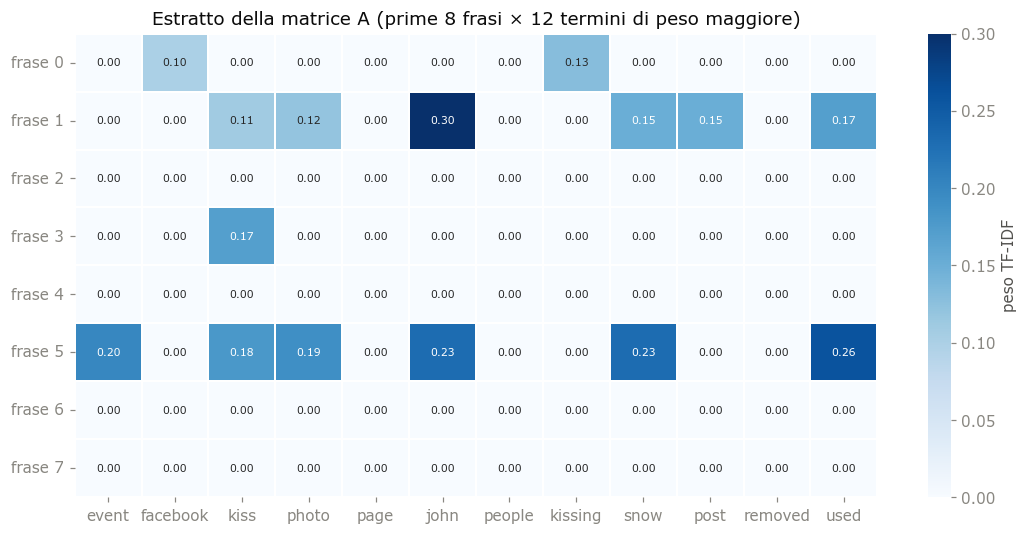

In [4]:
vett = TfidfVectorizer(stop_words='english')
A = vett.fit_transform(frasi)                 # sparsa (N, V) — è la stessa X del notebook 15
Ad = A.toarray()                              # versione densa per i calcoli a mano
vocabolario = vett.get_feature_names_out()
V = len(vocabolario)
print(f'Matrice A: {N} frasi × {V} termini | celle diverse da zero: {(Ad > 0).mean():.1%}  → matrice sparsa')
print(f'Norma di ogni riga: min {np.linalg.norm(Ad, axis=1).min():.3f}, max {np.linalg.norm(Ad, axis=1).max():.3f}  → tutte a 1')

# verifica a mano dell'IDF per un termine: il termine con peso maggiore nella frase 0
j = int(np.argmax(Ad[0])); t = vocabolario[j]
df_t = int((Ad[:, j] > 0).sum())
idf_manuale = np.log((1 + N) / (1 + df_t)) + 1
print(f"\ntermine '{t}': compare in {df_t} frasi su {N}  →  idf = ln((1+{N})/(1+{df_t})) + 1 = {idf_manuale:.4f}")
assert np.isclose(idf_manuale, vett.idf_[j])
print(f'idf di scikit-learn: {vett.idf_[j]:.4f}  ✔')

# estratto della matrice: prime frasi × termini di peso complessivo maggiore
top_termini = np.argsort(-Ad.sum(axis=0))[:12]
n_ant = min(8, N)
estratto = pd.DataFrame(Ad[:n_ant][:, top_termini].round(2), columns=[vocabolario[j] for j in top_termini],
                        index=[f'frase {i}' for i in range(n_ant)])
fig, ax = plt.subplots(figsize=(10, 0.42 * n_ant + 1.6))
sns.heatmap(estratto, annot=True, fmt='.2f', annot_kws={'size': 7}, cmap='Blues', vmin=0,
            linewidths=.3, linecolor='white', cbar_kws={'label': 'peso TF-IDF'}, ax=ax)
ax.set_title(f'Estratto della matrice A (prime {n_ant} frasi × 12 termini di peso maggiore)')
plt.tight_layout(); plt.show()

**Cosa abbiamo visto.** Ogni frase è un vettore lunghissimo (una componente per termine) e quasi tutto
zeri. In questo spazio due frasi sono simili solo se **condividono parole**: "the plane crashed" e "the
aircraft went down" risulterebbero estranee. È il limite che la SVD prova a superare.

## 4. La SVD: i concetti latenti
La **decomposizione ai valori singolari** riscrive qualsiasi matrice come prodotto di tre matrici:

> **A = U · Σ · Vᵀ**

| matrice | forma | significato |
|---|---|---|
| **Σ** | r × r, diagonale | i **valori singolari** σ₁ ≥ σ₂ ≥ … ≥ 0: quanta "energia" della matrice sta in ciascun concetto |
| **Vᵀ** | r × V | ogni riga è un **concetto**: un vettore sui termini, dice *di quali parole è fatto* |
| **U** | N × r | ogni riga è una **frase**: dice *quanto parla* di ciascun concetto (colonne ortonormali) |

con `r` = rango di A. Equivalentemente A è una **somma di r matrici di rango 1**, `A = Σₖ σₖ · uₖ · vₖᵀ`,
ordinate per importanza: i primi termini catturano i temi ricorrenti del cluster, gli ultimi il rumore
(parole occasionali, refusi).

**Troncare** a `k` concetti significa tenere solo i primi `k` termini della somma: è la migliore
approssimazione di rango `k` di A (teorema di Eckart-Young) e l'errore commesso è
`‖A − A_k‖_F = √(σ²_{k+1} + … + σ²_r)`.

Calcoliamo la SVD **completa** con `numpy` e verifichiamo che ricostruisca A esattamente.

U (19, 19) | Σ: 19 valori singolari | Vᵀ (19, 207) | rango di A = 19
✔ U · Σ · Vᵀ ricostruisce A
✔ colonne di U e righe di Vᵀ sono ortonormali (UᵀU = I, VᵀV = I)

Concetti tenuti: K = 11 su 19 | quota di energia (Σσ²) conservata: 67.5% | errore relativo di ricostruzione ‖A − A_K‖/‖A‖ = 0.570


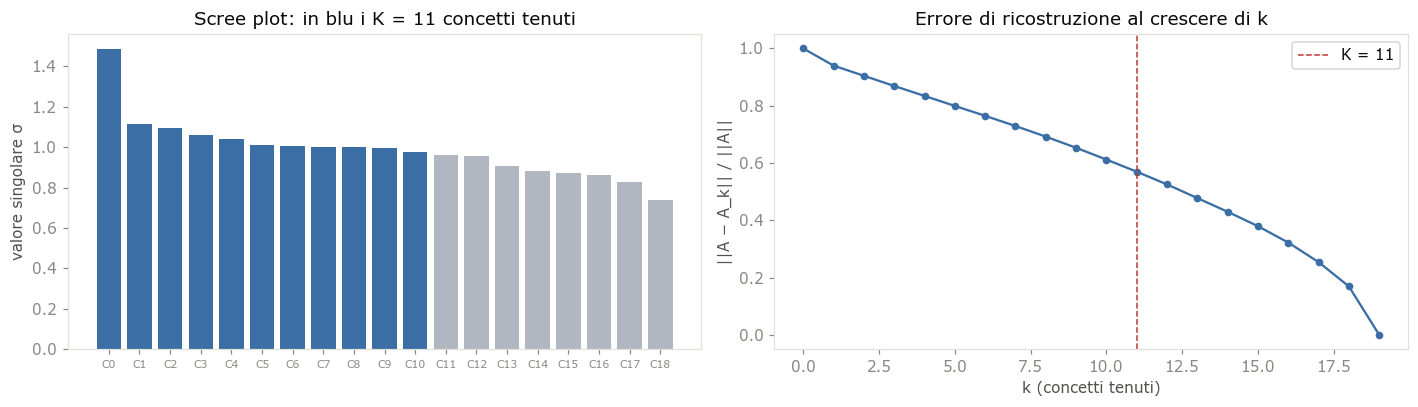

In [5]:
U, S, Vt = np.linalg.svd(Ad, full_matrices=False)       # SVD "economica": U (N, m), S (m,), Vt (m, V), m = min(N, V)
r = int(np.linalg.matrix_rank(Ad))
print(f'U {U.shape} | Σ: {len(S)} valori singolari | Vᵀ {Vt.shape} | rango di A = {r}')
assert np.allclose(U @ np.diag(S) @ Vt, Ad)
print('✔ U · Σ · Vᵀ ricostruisce A')
assert np.allclose(U.T @ U, np.eye(len(S))) and np.allclose(Vt @ Vt.T, np.eye(len(S)))
print('✔ colonne di U e righe di Vᵀ sono ortonormali (UᵀU = I, VᵀV = I)')

# il benchmark tiene k = min(K_LATENTE, min(A.shape) - 1) concetti (TruncatedSVD richiede k < n_features)
K = max(1, min(K_LATENTE, min(A.shape) - 1))
energia = S ** 2 / (S ** 2).sum()
errore_rel = np.sqrt([(S[k:] ** 2).sum() / (S ** 2).sum() for k in range(len(S) + 1)])
print(f'\nConcetti tenuti: K = {K} su {r} | quota di energia (Σσ²) conservata: {energia[:K].sum():.1%} '
      f'| errore relativo di ricostruzione ‖A − A_K‖/‖A‖ = {errore_rel[K]:.3f}')

fig, assi = plt.subplots(1, 2, figsize=(13, 3.8))
assi[0].bar(range(len(S)), S, color=['#3b6ea5' if k < K else '#b0b7c0' for k in range(len(S))])
assi[0].set_xticks(range(len(S))); assi[0].set_xticklabels([f'C{k}' for k in range(len(S))], fontsize=7)
assi[0].set_ylabel('valore singolare σ'); assi[0].set_title(f'Scree plot: in blu i K = {K} concetti tenuti')
assi[1].plot(range(len(S) + 1), errore_rel, 'o-', color='#3b6ea5', ms=4)
assi[1].axvline(K, color='#c0392b', ls='--', lw=1, label=f'K = {K}')
assi[1].set_xlabel('k (concetti tenuti)'); assi[1].set_ylabel('||A − A_k|| / ||A||')
assi[1].set_title('Errore di ricostruzione al crescere di k'); assi[1].legend()
plt.tight_layout(); plt.show()

**Cosa abbiamo visto.** Con poche decine di frasi lo spettro è quasi **piatto**: non c'è un gomito netto, e
tenere 11 concetti su ~19 conserva solo una parte dell'energia. C'è un modo semplice per leggere i numeri:
le righe di A hanno norma 1, quindi una frase che **non condivide parole con nessun'altra** è un vettore
ortogonale a tutti e diventa da sola un concetto con **σ = 1**. Un σ nettamente sopra 1 (sulla riga 50492
solo C0, 1,49) indica un tema **condiviso da più frasi**; i σ ≈ 1 sono concetti fatti quasi di una frase
sola. È la prima cosa da sapere su LSA applicata a un singolo cluster: c'è poca statistica, e la SVD ha
pochi temi "veri" da scoprire.

### I concetti: di quali parole sono fatti
La riga `k` di Vᵀ assegna un **carico** a ogni termine. Le parole con carico (in valore assoluto) più
alto descrivono il concetto.

⚠️ **Avvertenza sui segni.** La SVD è definita **a meno del segno**: `(uₖ, vₖ)` e `(−uₖ, −vₖ)` danno la
stessa A. Il segno dei carichi non ha significato (si guarda il **valore assoluto**), e due
implementazioni diverse possono restituire concetti con segno opposto. È una differenza pratica rispetto a
LDA, dove i topic sono distribuzioni di probabilità tutte positive e quindi più "leggibili".

C0 (σ = 1.49, 12% dell'energia): event, facebook, page, photo, kiss, john, snow, kissing
C1 (σ = 1.12, 7% dell'energia): john, snow, considered, richard, used, mild, groping, particular
C2 (σ = 1.09, 6% dell'energia): kissing, promote, event, just, page, paul, men, pub
C3 (σ = 1.06, 6% dell'energia): people, confused, gay, christian, picture, 2008, episode, october
C4 (σ = 1.04, 6% dell'energia): confused, people, gay, considered, 2008, aired, boyfriend, episode


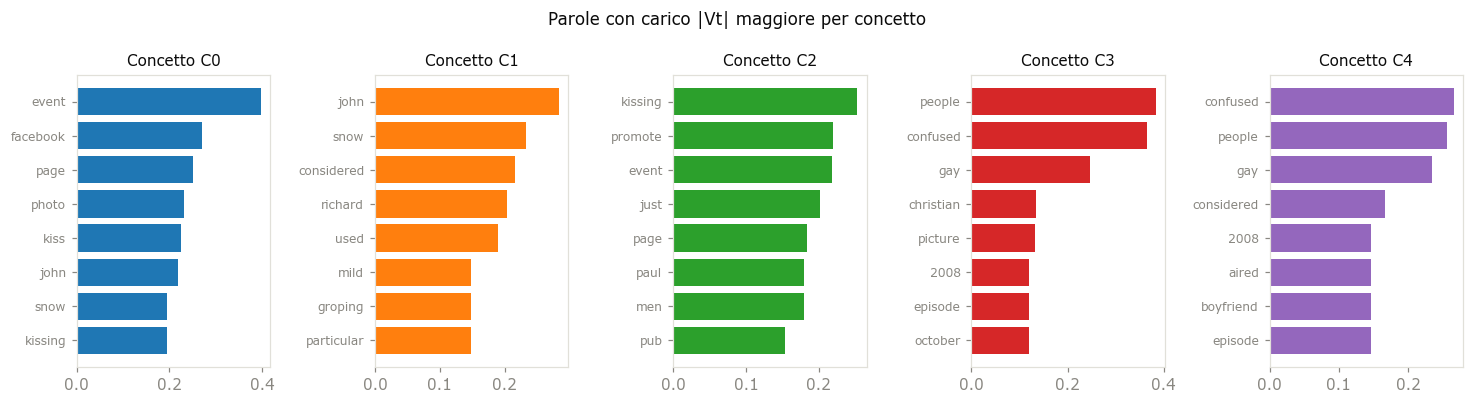

In [6]:
N_PAROLE = 8
N_CONCETTI_FIG = min(5, K)
for k in range(N_CONCETTI_FIG):
    parole = [vocabolario[j] for j in np.argsort(-np.abs(Vt[k]))[:N_PAROLE]]
    print(f'C{k} (σ = {S[k]:.2f}, {energia[k]:.0%} dell\'energia): {", ".join(parole)}')

fig, assi = plt.subplots(1, N_CONCETTI_FIG, figsize=(2.6 * N_CONCETTI_FIG + 0.5, 0.3 * N_PAROLE + 1.3))
assi = np.atleast_1d(assi)
for k, ax in enumerate(assi):
    idx = np.argsort(-np.abs(Vt[k]))[:N_PAROLE][::-1]
    ax.barh(range(len(idx)), np.abs(Vt[k][idx]), color=plt.cm.tab10(k))
    ax.set_yticks(range(len(idx))); ax.set_yticklabels([vocabolario[j] for j in idx], fontsize=8)
    ax.set_title(f'Concetto C{k}', fontsize=10)
fig.suptitle('Parole con carico |Vt| maggiore per concetto', fontsize=11)
plt.tight_layout(); plt.show()

**Cosa abbiamo visto.** Il primo concetto (σ più grande) raccoglie il **tema principale** del cluster — le
parole ripetute da più articoli (qui *event, facebook, page, photo, kiss*). I successivi, con σ ≈ 1, sono
spesso il vocabolario di una o due frasi particolari (qui un episodio TV citato di passaggio). I concetti non
sono "puliti" come i topic di LDA: lo stesso termine può avere carico alto su più concetti.

### Dalla SVD completa a quella del benchmark
Il benchmark non usa `numpy` ma `sklearn.TruncatedSVD`, che calcola **direttamente** i primi `K` concetti
(con un algoritmo randomizzato, `random_state=42`) e restituisce con `fit_transform` la matrice

> **Z = U_K · Σ_K**  (N × K)

cioè le frasi già espresse **nello spazio dei concetti**, con ogni colonna pesata per l'importanza del
concetto. Verifichiamo che coincida con le prime `K` colonne di `U · Σ` calcolate sopra (a meno del
segno di ciascuna colonna, per l'avvertenza appena vista).

Z: (19, 11) (frase × concetto) | colonne con segno invertito rispetto a numpy: 8 su 11
scarto massimo sui σ: 2.7e-15 | scarto massimo su Z (a meno del segno): 7.7e-14
✔ TruncatedSVD = prime K colonne di U·Σ (a meno del segno)


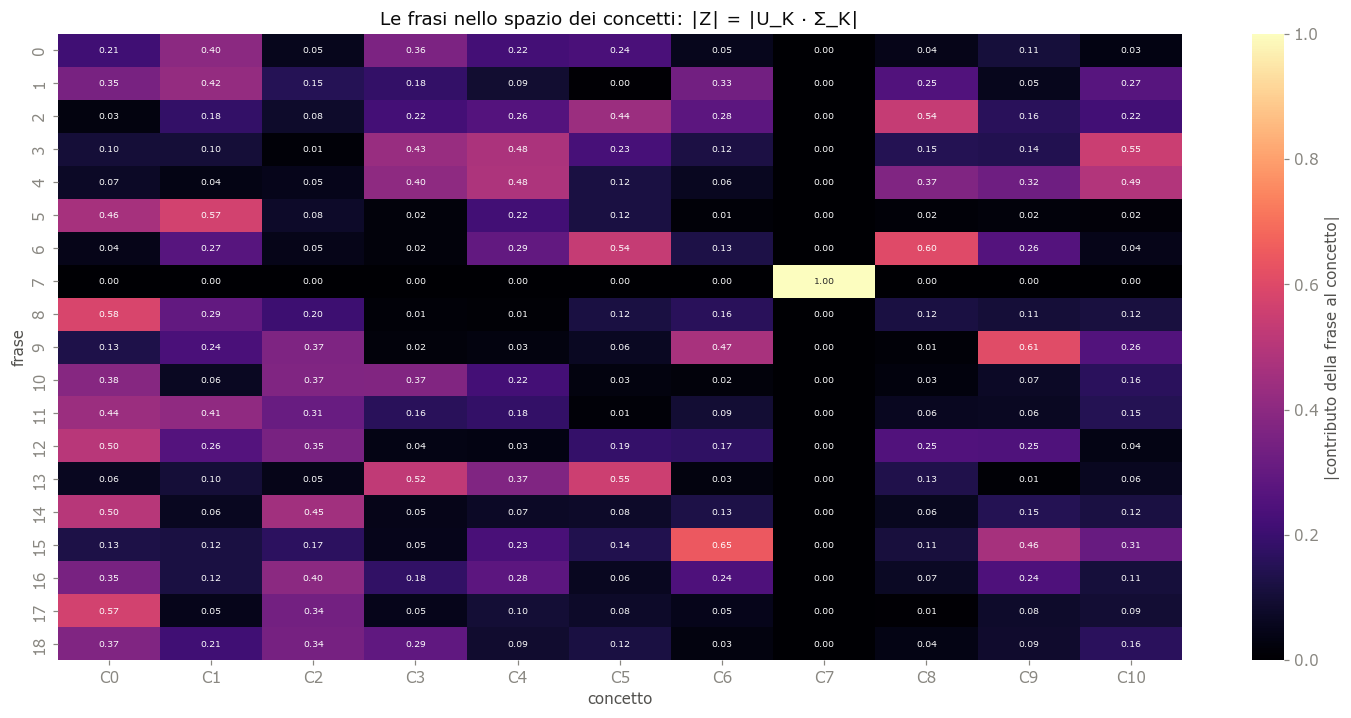

In [7]:
svd = TruncatedSVD(n_components=K, random_state=SEED)
Z = svd.fit_transform(A)                          # (N, K) = U_K · Σ_K — la Z del notebook 15
Z_numpy = U[:, :K] * S[:K]                        # stessa cosa dalla SVD completa

segni = np.sign((Z * Z_numpy).sum(axis=0))        # +1 / -1 per colonna: il segno è arbitrario
scarto_sigma = np.abs(svd.singular_values_ - S[:K]).max()
scarto_Z = np.abs(Z - Z_numpy * segni).max()
print(f'Z: {Z.shape} (frase × concetto) | colonne con segno invertito rispetto a numpy: {int((segni < 0).sum())} su {K}')
print(f'scarto massimo sui σ: {scarto_sigma:.1e} | scarto massimo su Z (a meno del segno): {scarto_Z:.1e}')
assert np.allclose(svd.singular_values_, S[:K], atol=1e-6) and np.allclose(Z, Z_numpy * segni, atol=1e-6)
print('✔ TruncatedSVD = prime K colonne di U·Σ (a meno del segno)')

fig, ax = plt.subplots(figsize=(1.0 * K + 2.5, 0.27 * N + 1.5))
sns.heatmap(np.abs(Z), cmap='magma', annot=(N <= 25 and K <= 12), fmt='.2f', annot_kws={'size': 6},
            xticklabels=[f'C{k}' for k in range(K)], yticklabels=range(N),
            cbar_kws={'label': '|contributo della frase al concetto|'}, ax=ax)
ax.set_xlabel('concetto'); ax.set_ylabel('frase')
ax.set_title('Le frasi nello spazio dei concetti: |Z| = |U_K · Σ_K|')
plt.tight_layout(); plt.show()

**Cosa abbiamo visto.** Ogni frase è ora un vettore di soli `K` numeri invece di `V` (centinaia). Righe
"accese" su una colonna = frasi che parlano soprattutto di un concetto; righe scure = frasi poco
informative. Le colonne di sinistra sono più chiare perché moltiplicate per σ più grandi.

## 5. La salienza di una frase
La salienza (Steinberger & Ježek) è la **lunghezza** del vettore della frase nello spazio dei concetti:

> ‖zᵢ‖ = √( Σₖ zᵢₖ² ) = √( Σₖ σₖ² · uᵢₖ² )

Una frase è saliente se ha componenti grandi (uᵢₖ) **sui concetti importanti** (σₖ grande): il peso σ²
fa sì che "parlare molto" del concetto principale valga più che parlare molto di un dettaglio. Il segno
arbitrario non conta più, perché si eleva al quadrato.

Poiché ogni riga di A ha norma 1, `‖zᵢ‖` è la lunghezza della **proiezione** della frase sul sottospazio dei
`K` concetti: vale tra 0 e 1, ed è 1 quando la frase sta *interamente* dentro i concetti tenuti.

È diversa dalla regola originale di Gong & Liu (2001), che prendeva *una frase per concetto* (la più
forte su C0, poi su C1, …) dando a tutti i concetti la stessa importanza: Steinberger pesa i concetti
con σ ed è la regola implementata anche da `sumy`.

✔ ‖zᵢ‖ = √(Σₖ σₖ² uᵢₖ²) calcolata a mano coincide con la norma delle righe di Z
✔ 0 ≤ ‖zᵢ‖ ≤ 1 (proiezione di un vettore di norma 1): min 0.666, max 1.000


,frase,salienza ‖z‖,concetto dominante,parole,testo
posizione,,,,,
1,7,1.000,C7,3,Oh the irony…
2,4,0.949,C10,21,"However, since this episode aired (October 2008) Christian now has a boyfriend a…"
3,6,0.949,C8,15,The photos I had considered using before I chose that one are much more racy…
4,15,0.934,C6,25,"""The photo in question does not violate our Statement of Rights and Responsibili…"
5,9,0.930,C9,16,"Paul Shetler, the organizer, left this comment on the previous thread: \n \n “Hey …"
6,3,0.917,C10,33,"This picture has itself caused scandal in the UK, as it was a gay kiss that was …"
7,2,0.886,C8,23,I am not a regular viewer so I can’t say if the man on the right is an extra or …
8,13,0.870,C5,7,This seems to have confused some people…
9,12,0.800,C0,42,"Also, Richard did not state in his post that Facebook HAD taken the event page d…"


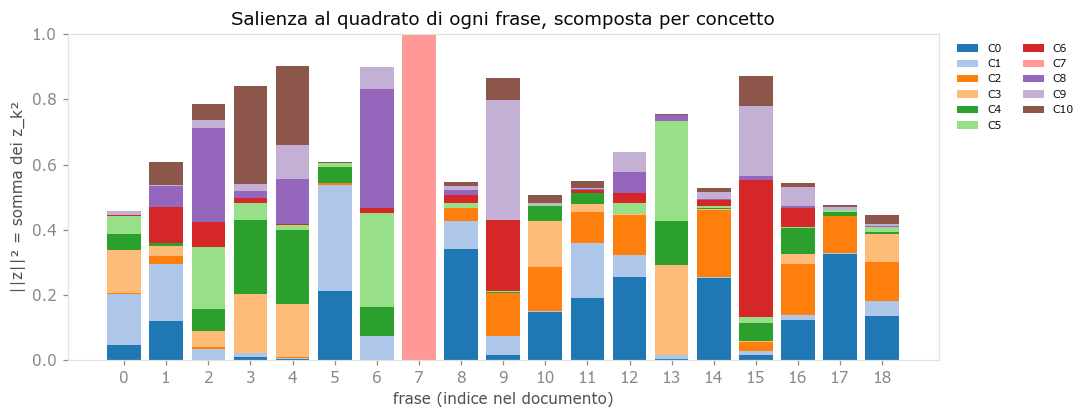

In [8]:
salienza = np.linalg.norm(Z, axis=1)                                     # come seleziona_topk() del benchmark
salienza_manuale = np.array([np.sqrt(sum(S[k] ** 2 * U[i, k] ** 2 for k in range(K))) for i in range(N)])
assert np.allclose(salienza, salienza_manuale, atol=1e-6)
print('✔ ‖zᵢ‖ = √(Σₖ σₖ² uᵢₖ²) calcolata a mano coincide con la norma delle righe di Z')
assert (salienza <= 1 + 1e-9).all()
print(f'✔ 0 ≤ ‖zᵢ‖ ≤ 1 (proiezione di un vettore di norma 1): min {salienza.min():.3f}, max {salienza.max():.3f}')

ord_sal = np.argsort(-salienza)
display(pd.DataFrame({
    'posizione': range(1, N + 1), 'frase': [int(i) for i in ord_sal],
    'salienza ‖z‖': [round(float(salienza[i]), 3) for i in ord_sal],
    'concetto dominante': [f'C{int(np.argmax(np.abs(Z[i])))}' for i in ord_sal],
    'parole': [len(frasi[i].split()) for i in ord_sal],
    'testo': [frasi[i][:80] + '…' for i in ord_sal],
}).set_index('posizione'))

# composizione della salienza: quanto contribuisce ogni concetto (zᵢₖ²) — impilato per frase
contrib = Z ** 2
fig, ax = plt.subplots(figsize=(10, 3.9))
fondo = np.zeros(N)
for k in range(K):
    ax.bar(range(N), contrib[:, k], bottom=fondo, color=plt.cm.tab20(k % 20), label=f'C{k}')
    fondo += contrib[:, k]
ax.set_xticks(range(N)); ax.set_xlabel('frase (indice nel documento)'); ax.set_ylabel('||z||² = somma dei z_k²')
ax.set_title('Salienza al quadrato di ogni frase, scomposta per concetto')
ax.legend(ncol=2, fontsize=7, bbox_to_anchor=(1.01, 1), loc='upper left', frameon=False)
plt.tight_layout(); plt.show()

**Cosa abbiamo visto — e non è quello che ci si aspetterebbe.** In cima alla classifica non ci sono le
frasi sul tema principale (C0), ma frasi **corte e isolate**: sulla riga 50492 la prima è *"Oh the irony"*
(3 parole, salienza 1,000), seguita da frasi su un episodio TV citato di passaggio. Il motivo è quello visto
nella sezione 4: una frase che non condivide parole con le altre forma **da sola** un concetto con σ = 1; se
quel concetto rientra tra i `K` tenuti, la frase è proiettata per intero e ha salienza ≈ 1. Le frasi sul tema
centrale, invece, si "spartiscono" C0 con le altre e hanno parte del loro contenuto nei concetti scartati.

È l'effetto del peso σ² in uno spettro piatto: quando i σ sono quasi tutti uguali, pesare per σ non distingue
più i temi importanti dai dettagli. Il fenomeno non riguarda solo questa riga: nel benchmark `lsa` estrae
11 frasi per ~249 parole (~23 parole a frase) contro le ~362 di Centroid+MMR e le ~368 di TextRank (~33
parole a frase): LSA tende a scegliere frasi **più corte**.

## 6. (Intermezzo) Perché "semantica latente": la similarità nello spazio dei concetti
Il motivo storico di LSA (Deerwester et al., 1990, nato per il *information retrieval*) è che nello
spazio troncato due frasi possono risultare **vicine anche senza parole in comune**, se le loro parole
co-occorrono con le stesse altre parole nel resto del cluster (la *sinonimia* "plane"/"aircraft").

Confrontiamo per ogni coppia di frasi il coseno **lessicale** (sulle righe di A) con quello **latente**
(sulle righe di Z). Questa sezione non serve alla selezione: serve a capire che cosa "vede" la SVD.

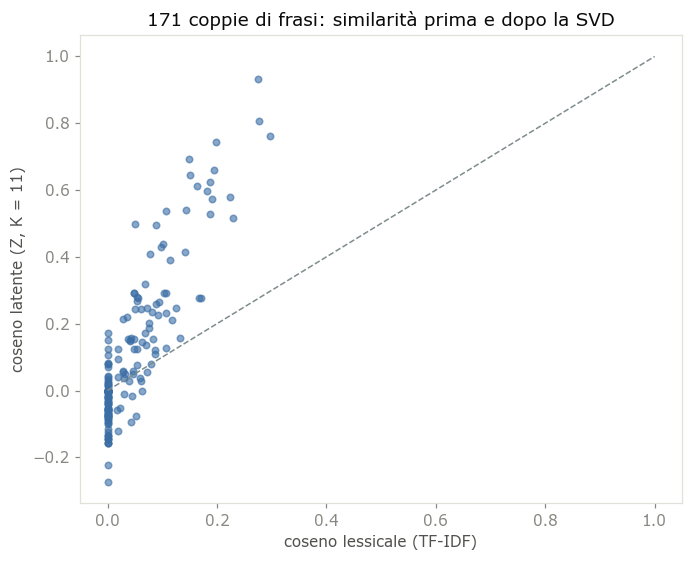

Coppie senza alcun termine in comune (coseno lessicale = 0): 86 su 171
  di queste, con coseno latente > 0,3: 0 | < -0,3: 0

La coppia "più vicina senza parole in comune": (2, 13), coseno latente 0.17
  [2] I am not a regular viewer so I can’t say if the man on the right is an extra or an actual character…
  [13] This seems to have confused some people…


In [9]:
sim_lessicale = cosine_similarity(Ad)
sim_latente = cosine_similarity(Z)
coppie = np.triu_indices(N, 1)
x, y = sim_lessicale[coppie], sim_latente[coppie]

fig, ax = plt.subplots(figsize=(6.4, 5.2))
ax.scatter(x, y, s=18, alpha=.6, color='#3b6ea5')
ax.plot([0, 1], [0, 1], ls='--', color='#7f8c8d', lw=1)
ax.set_xlabel('coseno lessicale (TF-IDF)'); ax.set_ylabel(f'coseno latente (Z, K = {K})')
ax.set_title(f'{len(x)} coppie di frasi: similarità prima e dopo la SVD')
plt.tight_layout(); plt.show()

zero = x == 0
print(f'Coppie senza alcun termine in comune (coseno lessicale = 0): {zero.sum()} su {len(x)}')
print(f'  di queste, con coseno latente > 0,3: {(y[zero] > 0.3).sum()} | < -0,3: {(y[zero] < -0.3).sum()}')
if zero.any():
    m = np.argmax(np.where(zero, y, -np.inf))
    i, j = coppie[0][m], coppie[1][m]
    print(f'\nLa coppia "più vicina senza parole in comune": ({i}, {j}), coseno latente {y[m]:.2f}')
    print(f'  [{i}] {frasi[i][:110]}…\n  [{j}] {frasi[j][:110]}…')

**Cosa abbiamo visto.** I punti sull'asse verticale (coseno lessicale 0) sono coppie che il TF-IDF
considera estranee e che la SVD può avvicinare (o allontanare: nello spazio latente il coseno può anche
essere **negativo**). Su un cluster di ~20 frasi però le co-occorrenze sono poche e l'effetto è **modesto**:
sulla riga 50492 nessuna delle 86 coppie senza parole in comune supera 0,3 di coseno latente. La "sinonimia"
di LSA ha bisogno di statistica: è nata per collezioni di migliaia di documenti, non per 20 frasi. Per una similarità *semantica* robusta servono embedding
pre-addestrati (variante BERT di Centroid+MMR, notebook 11; clustering SBERT, notebook 16).

## 7. Selezione: top-k contro deflazione
Ora che ogni frase ha un vettore `zᵢ`, le due varianti del benchmark lo usano in modo diverso.

### 7a. `lsa` — top-k per salienza
Si ordinano le frasi per `‖zᵢ‖` decrescente e si prendono le prime: è esattamente l'ordinamento della
sezione 5. **Nessuna memoria**: se le tre frasi più salienti dicono la stessa cosa (succede spesso in
multi-documento, dove ogni articolo racconta il fatto principale) entrano tutte e tre.

### 7b. `lsa_steinberger` — greedy con deflazione
Si sceglie **una frase alla volta**, aggiornando lo spazio dopo ogni scelta:

1. si parte da `R = Z` (la matrice *residua*);
2. si sceglie la frase `i*` con il vettore residuo `rᵢ` **più lungo** (escludendo quelle già scelte);
3. si calcola la sua direzione `û = r_{i*} / ‖r_{i*}‖` e la si **sottrae** da tutte le frasi
   (proiezione ortogonale): `rⱼ ← rⱼ − (rⱼ · û) û`;
4. si ripete dal punto 2.

Dopo il passo 3 nessuna frase ha più componenti lungo `û`: il contenuto già coperto **smette di valere**.
Una frase che ripete quella scelta (vettore quasi parallelo) crolla a lunghezza ~0; una che aggiunge un
concetto nuovo (vettore quasi ortogonale) mantiene la sua lunghezza. È l'**anti-ridondanza** della
variante multi-documento di Steinberger, assente in `sumy`.

Ogni deflazione toglie una dimensione allo spazio: dopo `K` scelte il residuo è **tutto zero** e il greedy
si ferma. Se servono altre frasi (modalità `'budget'` o `N_SENTENCES > K`) l'ordine prosegue con la
**salienza originale** (ripiego del benchmark). Per questo `K_LATENTE` deve valere almeno `N_SENTENCES`.

Sotto, il greedy riscritto **passo per passo** conservando la storia, con le verifiche geometriche.

In [10]:
EPS = 1e-12      # soglia sotto cui un vettore residuo è considerato esaurito (come il benchmark)

def deflazione_passo_passo(Z, n):
    """Stesso greedy di seleziona_deflazione() del notebook 15, ma conserva la storia di ogni passo."""
    R = np.array(Z, dtype=float, copy=True)
    scelti, storia = [], []
    for _ in range(min(n, len(R))):
        lunghezze = np.linalg.norm(R, axis=1)
        candidate = lunghezze.copy(); candidate[scelti] = -1.0          # le già scelte non tornano candidate
        i = int(np.argmax(candidate))
        if candidate[i] <= EPS:                                          # spazio residuo esaurito
            break
        u = R[i] / np.linalg.norm(R[i])
        R = R - np.outer(R @ u, u)                                       # r_j <- r_j - (r_j · u) u
        assert np.allclose(R @ u, 0, atol=1e-9)                          # nessuno ha più componenti lungo u
        storia.append({'scelto': i, 'lunghezze': lunghezze, 'rango_residuo': int(np.linalg.matrix_rank(R, tol=1e-9))})
        scelti.append(i)
    n_deflazione = len(scelti)
    for i in np.argsort(-np.linalg.norm(Z, axis=1)):                     # ripiego: salienza ORIGINALE
        if len(scelti) >= min(n, len(Z)):
            break
        if int(i) not in scelti:
            scelti.append(int(i))
    return scelti, storia, n_deflazione

K_ORDINE = min(N, N_SENTENCES if MODALITA == 'frasi' else K_ORDINE_BUDGET)
ordine_topk = [int(i) for i in np.argsort(-salienza)[:K_ORDINE]]
ordine_defl, storia_defl, n_defl = deflazione_passo_passo(Z, K_ORDINE)

print(f'Ordine lsa (top-k)            : {ordine_topk[:15]}')
print(f'Ordine lsa_steinberger        : {ordine_defl[:15]}')
print(f'  di cui scelte per deflazione: {n_defl} (= K = {K}: dopo K sottrazioni il residuo è nullo), '
      f'poi ripiego sulla salienza originale')
print('✔ dopo ogni passo il residuo è ortogonale alla direzione scelta')

righe = []
for t, passo in enumerate(storia_defl, 1):
    i = passo['scelto']
    righe.append({'passo': t, 'frase scelta': i, 'salienza originale ‖z‖': round(float(salienza[i]), 3),
                  'lunghezza residua ‖r‖': round(float(passo['lunghezze'][i]), 3),
                  'quota "nuova"': f"{passo['lunghezze'][i] / salienza[i]:.0%}",
                  'rango del residuo dopo': passo['rango_residuo'],
                  'posizione in lsa': ordine_topk.index(i) + 1 if i in ordine_topk else '—',
                  'testo': frasi[i][:55] + '…'})
display(pd.DataFrame(righe).set_index('passo'))

Ordine lsa (top-k)            : [7, 4, 6, 15, 9, 3, 2, 13, 12, 1, 5, 11, 8, 16, 14]
Ordine lsa_steinberger        : [7, 4, 6, 15, 9, 3, 2, 13, 12, 14, 1, 5, 11, 8, 16]
  di cui scelte per deflazione: 11 (= K = 11: dopo K sottrazioni il residuo è nullo), poi ripiego sulla salienza originale
✔ dopo ogni passo il residuo è ortogonale alla direzione scelta


,frase scelta,salienza originale ‖z‖,lunghezza residua ‖r‖,"quota ""nuova""",rango del residuo dopo,posizione in lsa,testo
passo,,,,,,,
1,7,1.000,1.000,100%,10,1,Oh the irony…
2,4,0.949,0.949,100%,9,2,"However, since this episode aired (October 2008) Christ…"
3,6,0.949,0.948,100%,8,3,The photos I had considered using before I chose that o…
4,15,0.934,0.934,100%,7,4,"""The photo in question does not violate our Statement o…"
5,9,0.930,0.926,100%,6,5,"Paul Shetler, the organizer, left this comment on the p…"
6,3,0.917,0.911,99%,5,6,"This picture has itself caused scandal in the UK, as it…"
7,2,0.886,0.865,98%,4,7,I am not a regular viewer so I can’t say if the man on …
8,13,0.870,0.847,97%,3,8,This seems to have confused some people…
9,12,0.800,0.757,95%,2,9,"Also, Richard did not state in his post that Facebook H…"


**Leggere la tabella.** Al passo 1 la lunghezza residua coincide con la salienza originale: vince la frase
più saliente, come in `lsa`. Dal passo 2 in poi la colonna *quota "nuova"* dice quanta parte della frase
non era già coperta dalle scelte precedenti: il greedy può preferire una frase meno saliente in assoluto
ma con più contenuto *nuovo*. Il rango del residuo cala di 1 a ogni passo, fino a 0.

Sulla riga 50492 la quota "nuova" resta ~95-100% per tutti gli 11 passi e l'ordine coincide con quello di
`lsa` per le prime 9 scelte: le frasi scelte sono quasi **ortogonali** tra loro (sono proprio le frasi
isolate della sezione 5), quindi non c'è ridondanza da togliere. La prima divergenza è al passo 10.

La figura mostra lo stesso processo dal lato delle **candidate**: le lunghezze residue di tutte le frasi
prima di ciascuna delle prime scelte. Le frasi simili a quella appena scelta **collassano**.

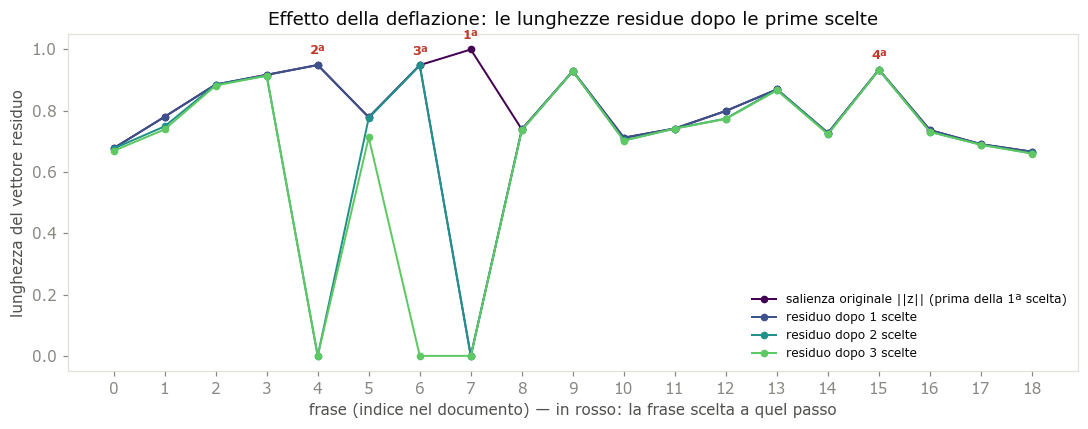

In [11]:
n_passi = min(4, len(storia_defl))
fig, ax = plt.subplots(figsize=(10, 4.0))
for t in range(n_passi):
    ax.plot(range(N), storia_defl[t]['lunghezze'], marker='o', ms=4, lw=1.3, color=plt.cm.viridis(t / max(1, n_passi)),
            label='salienza originale ||z|| (prima della 1ª scelta)' if t == 0 else f'residuo dopo {t} scelte')
for t in range(n_passi):
    i = storia_defl[t]['scelto']
    ax.annotate(f'{t + 1}ª', (i, storia_defl[t]['lunghezze'][i]), xytext=(0, 7), textcoords='offset points',
                ha='center', fontsize=8, color='#c0392b', fontweight='bold')
ax.set_xticks(range(N)); ax.set_xlabel('frase (indice nel documento) — in rosso: la frase scelta a quel passo')
ax.set_ylabel('lunghezza del vettore residuo')
ax.set_title('Effetto della deflazione: le lunghezze residue dopo le prime scelte')
ax.legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

**Cosa abbiamo visto.** Ogni curva sta sotto la precedente (togliere una componente non può allungare un
vettore). La frase appena scelta va a **0** per costruzione (le si è tolta la sua stessa direzione); le altre
scendono solo **dove c'è ridondanza** con lei (sulla riga 50492 la frase 5, simile alla 6) e altrimenti non si muovono.
Su questa riga le curve quasi si sovrappongono, per il motivo appena detto; su un cluster in cui più articoli
raccontano lo stesso fatto con le stesse parole si vedrebbero invece crolli netti.

Verifichiamo ora che questa versione **coincida con l'implementazione del benchmark**. Qui sotto
`segmenta`, `seleziona_topk`, `seleziona_deflazione` e `genera` sono copiate **identiche** dal notebook
15: se un giorno le due divergessero, queste `assert` si romperebbero.

In [12]:
# --- copia fedele del codice di produzione (notebooks/15_lsa.ipynb) ---------------------------------
STOP_WORDS = ['en']

def segmenta(documento):
    s = psr.summarization(documento, stop_words=STOP_WORDS)
    return [f.strip() for f in getattr(s, 'original', []) if f and f.strip()]

def seleziona_topk(Z, n_sentences):
    salienza = np.linalg.norm(Z, axis=1)
    return [int(i) for i in np.argsort(-salienza)[:n_sentences]]

def seleziona_deflazione(Z, n_sentences):
    R = np.array(Z, dtype=float, copy=True)
    scelti, storia = [], []
    for _ in range(min(n_sentences, len(R))):
        lunghezze = np.linalg.norm(R, axis=1)
        storia.append(lunghezze.copy())
        lunghezze[scelti] = -1.0
        i = int(np.argmax(lunghezze))
        if lunghezze[i] <= EPS:
            break
        scelti.append(i)
        u = R[i] / np.linalg.norm(R[i])
        R -= np.outer(R @ u, u)
    if len(scelti) < min(n_sentences, len(Z)):
        for i in np.argsort(-np.linalg.norm(Z, axis=1)):
            if int(i) not in scelti:
                scelti.append(int(i))
            if len(scelti) >= min(n_sentences, len(Z)):
                break
    return scelti, storia

SELETTORI = {'lsa': lambda Z, n: seleziona_topk(Z, n),
             'lsa_steinberger': lambda Z, n: seleziona_deflazione(Z, n)[0]}

def make_genera(metodo):
    seleziona = SELETTORI[metodo]
    def genera(documento, budget=None):
        frasi = segmenta(documento)
        if budget is None and len(frasi) <= N_SENTENCES:
            return ' '.join(frasi)
        n_ordine = N_SENTENCES if budget is None else min(len(frasi), K_ORDINE_BUDGET)
        try:
            X = TfidfVectorizer(stop_words='english').fit_transform(frasi)
            k = max(1, min(K_LATENTE, min(X.shape) - 1))
            Z = TruncatedSVD(n_components=k, random_state=SEED).fit_transform(X)
            ordine = seleziona(Z, n_ordine)
        except ValueError:
            ordine = range(n_ordine)
        if budget is not None:
            ordine = su.seleziona_per_budget(frasi, ordine, budget)
        return ' '.join(frasi[i] for i in sorted(ordine))
    return genera
# ---------------------------------------------------------------------------------------------------

assert segmenta(documento) == frasi
assert seleziona_topk(Z, K_ORDINE) == ordine_topk
assert seleziona_deflazione(Z, K_ORDINE)[0] == ordine_defl, 'il greedy scritto a mano deve coincidere con il benchmark'
print(f'✔ Segmentazione e ordini di selezione coincidono con il notebook 15 (lsa: {ordine_topk[:6]}…, '
      f'lsa_steinberger: {ordine_defl[:6]}…)')

# il prefisso dell'ordine non dipende da n: fermarsi al passo t == tagliare l'ordine lungo (è ciò che rende valido il budget)
assert seleziona_deflazione(Z, 5)[0] == ordine_defl[:5] and seleziona_topk(Z, 5) == ordine_topk[:5]
print("✔ Le prime 5 scelte sono le stesse con n = 5 e con n più grande: tagliare l'ordine = fermare il greedy.")

ORDINI = {'lsa': ordine_topk, 'lsa_steinberger': ordine_defl}
ordine = ORDINI[VARIANTE]

✔ Segmentazione e ordini di selezione coincidono con il notebook 15 (lsa: [7, 4, 6, 15, 9, 3]…, lsa_steinberger: [7, 4, 6, 15, 9, 3]…)
✔ Le prime 5 scelte sono le stesse con n = 5 e con n più grande: tagliare l'ordine = fermare il greedy.


### Effetto di `K_LATENTE`
`K` è la manopola del metodo: quanti concetti tenere. La figura mostra **quali frasi entrano** nelle prime
`N_SENTENCES` posizioni al variare di `K`, per le due varianti, e la tabella la **ridondanza media** del
set scelto (coseno *lessicale* medio tra le coppie scelte, più basso = riassunto meno ripetitivo).

Due casi limite utili per capire: con `K = 1` la salienza è solo `|u_{i0}|·σ₀` (vicinanza al tema
principale, molto simile a un centroide) e la deflazione si esaurisce dopo **una** scelta, quindi
`lsa_steinberger` ricade quasi tutto sul top-k; con `K` grande si tengono anche le direzioni di rumore.

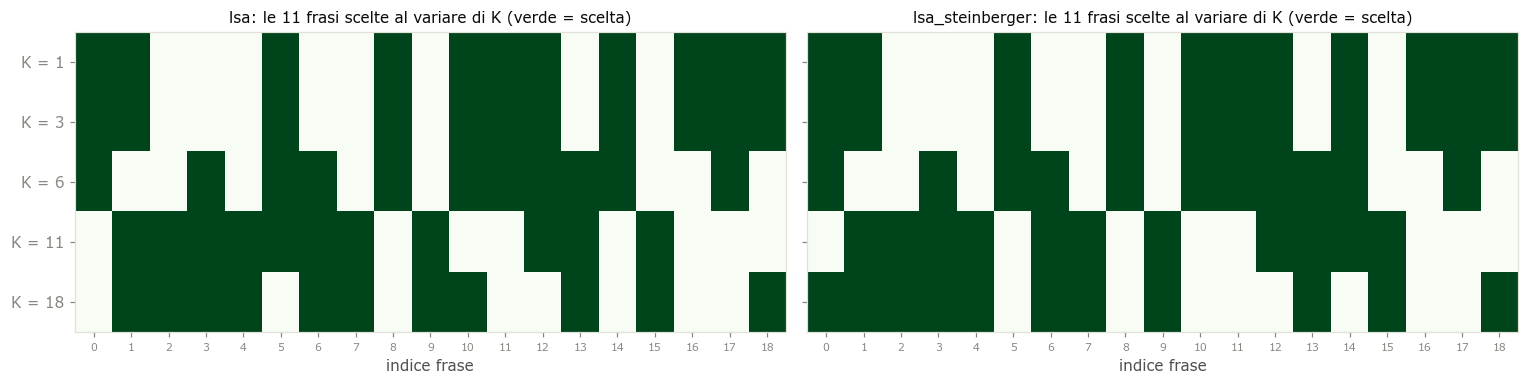

ridondanza media del set  parole del set  frasi in comune con K = 11
K  variante                                                                             
1  lsa                                 0.109             520                           3
   lsa_steinberger                     0.109             520                           3
3  lsa                                 0.109             520                           3
   lsa_steinberger                     0.109             520                           3
6  lsa                                 0.072             423                           5
   lsa_steinberger                     0.072             423                           5
11 lsa                                 0.017             269                          11
   lsa_steinberger                     0.014             312                          11
18 lsa                                 0.014             331                           9
   lsa_steinberger                     0.012             330                           9

In [13]:
def ridondanza_media(indici):
    coppie_ = [sim_lessicale[a][b] for i, a in enumerate(indici) for b in indici[i + 1:]]
    return float(np.mean(coppie_)) if coppie_ else 0.0

K_CONFRONTO = sorted({1, 3, 6, K, max(1, min(A.shape) - 1)})
K_L = min(N, N_SENTENCES)
sel_k, righe = {}, []
for k_ in K_CONFRONTO:
    Z_k = TruncatedSVD(n_components=k_, random_state=SEED).fit_transform(A)
    for var in ('lsa', 'lsa_steinberger'):
        sel_k[(var, k_)] = SELETTORI[var](Z_k, K_L)
        righe.append({'K': k_, 'variante': var, 'ridondanza media del set': round(ridondanza_media(sel_k[(var, k_)]), 3),
                      'parole del set': sum(len(frasi[i].split()) for i in sel_k[(var, k_)]),
                      f'frasi in comune con K = {K}': len(set(sel_k[(var, k_)]) & set(SELETTORI[var](Z, K_L)))})

fig, assi = plt.subplots(1, 2, figsize=(14, 1.6 + 0.4 * len(K_CONFRONTO)), sharey=True)
for ax, var in zip(assi, ('lsa', 'lsa_steinberger')):
    M = np.zeros((len(K_CONFRONTO), N))
    for r_, k_ in enumerate(K_CONFRONTO):
        M[r_, sel_k[(var, k_)]] = 1.0
    ax.imshow(M, cmap='Greens', vmin=0, vmax=1, aspect='auto')
    ax.set_yticks(range(len(K_CONFRONTO))); ax.set_yticklabels([f'K = {k_}' for k_ in K_CONFRONTO])
    ax.set_xticks(range(N)); ax.set_xticklabels(range(N), fontsize=7); ax.set_xlabel('indice frase')
    ax.set_title(f'{var}: le {K_L} frasi scelte al variare di K (verde = scelta)', fontsize=10)
plt.tight_layout(); plt.show()
display(pd.DataFrame(righe).set_index(['K', 'variante']))

**Cosa abbiamo visto.** `K` cambia molto il risultato: con `K` piccolo si tengono solo i concetti con σ
alto, cioè il tema **condiviso**, e vengono scelte le frasi lunghe e centrali (sulla riga 50492: ~520 parole
con `K = 1`); con `K = 11` entrano i concetti "di una frase sola" e vengono scelte le frasi corte e isolate
(~270-310 parole). Con `K` piccolo, inoltre, la deflazione si esaurisce dopo `K` passi e `lsa_steinberger`
coincide con `lsa`. Il benchmark fissa `K = 11` senza ottimizzarlo.

## 8. Selezione delle frasi
Entrambe le varianti producono un **ordine** (`ordine`, quello di `VARIANTE`); poi la `MODALITA` decide dove fermarsi:

- **`'frasi'`**: si tengono le prime `N_SENTENCES = 11` frasi (11 è la mediana del numero di frasi dei
  riassunti del corpus). Se il documento ha già ≤ 11 frasi, si prendono tutte;
- **`'budget'`**: si accumulano frasi **nello stesso ordine** finché si raggiunge il **budget**
  = lunghezza in parole del riferimento (`su.seleziona_per_budget`: la frase che sfora viene
  inclusa solo se ne entra più della metà). Si usa solo la *lunghezza* del gold, mai il suo
  contenuto. Il benchmark calcola un ordine lungo fino a `K_ORDINE_BUDGET = 50` frasi e poi lo taglia:
  grazie alla proprietà del prefisso verificata sopra, è equivalente a fermarsi al budget.

In entrambi i casi l'ordine è lo stesso: cambia solo il punto di taglio.

VARIANTE = 'lsa_steinberger' | MODALITA = 'budget': selezionate 9 frasi (185 parole) | budget = 168 parole


,frase,salienza ‖z‖,parole,scelta,testo
ordine,,,,,
1,7,1.000,3,✔,Oh the irony…
2,4,0.949,21,✔,"However, since this episode aired (October 2008) Christian now has a boyfriend a…"
3,6,0.949,15,✔,The photos I had considered using before I chose that one are much more racy…
4,15,0.934,25,✔,"""The photo in question does not violate our Statement of Rights and Responsibili…"
5,9,0.930,16,✔,"Paul Shetler, the organizer, left this comment on the previous thread: \n \n “Hey …"
6,3,0.917,33,✔,"This picture has itself caused scandal in the UK, as it was a gay kiss that was …"
7,2,0.886,23,✔,I am not a regular viewer so I can’t say if the man on the right is an extra or …
8,13,0.870,7,✔,This seems to have confused some people…
9,12,0.800,42,✔,"Also, Richard did not state in his post that Facebook HAD taken the event page d…"


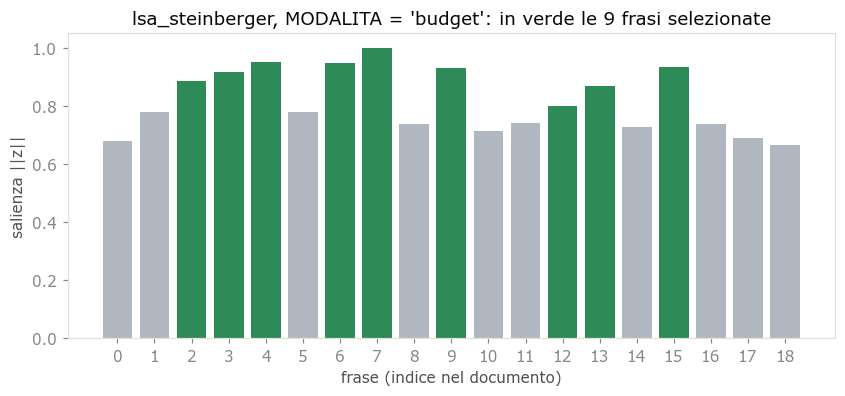

In [14]:
budget = su.budget_riferimento(esempio)                 # = parole del riferimento
idx_frasi = ordine[:N_SENTENCES]
idx_budget = su.seleziona_per_budget(frasi, ordine, budget)
idx_scelti = idx_frasi if MODALITA == 'frasi' else idx_budget
selezionate = set(idx_scelti)
print(f"VARIANTE = '{VARIANTE}' | MODALITA = '{MODALITA}': selezionate {len(idx_scelti)} frasi "
      f"({sum(len(frasi[i].split()) for i in idx_scelti)} parole) | budget = {budget} parole")

display(pd.DataFrame({
    'ordine': range(1, len(ordine) + 1),
    'frase': ordine,
    'salienza ‖z‖': [round(float(salienza[i]), 3) for i in ordine],
    'parole': [len(frasi[i].split()) for i in ordine],
    'scelta': ['✔' if i in selezionate else '' for i in ordine],
    'testo': [frasi[i][:80] + '…' for i in ordine],
}).set_index('ordine'))

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(range(N), salienza, color=['#2e8b57' if i in selezionate else '#b0b7c0' for i in range(N)])
ax.set_xticks(range(N)); ax.set_xlabel('frase (indice nel documento)'); ax.set_ylabel('salienza ||z||')
ax.set_title(f"{VARIANTE}, MODALITA = '{MODALITA}': in verde le {len(selezionate)} frasi selezionate")
plt.show()

**Cosa abbiamo visto.** Con `lsa` le frasi scelte sono semplicemente le barre più alte; con
`lsa_steinberger` può entrare una barra bassa al posto di una alta, se porta un concetto nuovo. Come per
gli altri estrattivi non c'è alcun criterio di *posizione* (come nel baseline First-k). In modalità
`'budget'` contano soprattutto le **prime** scelte, dove le due varianti tendono a coincidere (il passo 1 è
sempre la frase più saliente). Sulla riga 50492 le frasi scelte sono corte, e nel budget ne entrano 9.

## 9. Generazione del riassunto finale
Il riassunto è la concatenazione delle frasi **originali** scelte, **rimesse in ordine di documento**
(`sorted`): come Centroid+MMR e a differenza di TextRank/LexRank (che emettono per punteggio decrescente),
il testo segue l'ordine in cui le notizie compaiono negli articoli. In modalità `'budget'` si applica poi il
**tetto**: troncamento alle prime `round(1,25 × lunghezza del riferimento)` parole
(`su.tetto_riferimento`), come fa il benchmark prima di calcolare le metriche. Verifichiamo che il testo
coincida con quello di `genera()` del notebook 15.

In [15]:
tetto = su.tetto_riferimento(esempio)         # round(1,25 × riferimento)
genera_produzione = make_genera(VARIANTE)

riassunto_frasi = ' '.join(frasi[i] for i in sorted(idx_frasi)) if N > N_SENTENCES else ' '.join(frasi)
riassunto_budget = ' '.join(frasi[i] for i in sorted(idx_budget))
riassunto_budget_tetto = su.tronca_parole(riassunto_budget, tetto)

# verifica contro la funzione di produzione (stesso testo che finirebbe in results/summaries/)
assert riassunto_frasi == genera_produzione(documento)
assert riassunto_budget == genera_produzione(documento, budget=budget)
print(f"✔ 'frasi' e 'budget' coincidono con genera() del notebook 15 ({VARIANTE})")

riassunto = riassunto_frasi if MODALITA == 'frasi' else riassunto_budget_tetto   # ← quello che si valuta
if MODALITA == 'budget':
    print(f'  budget = {budget} parole | tetto = {tetto} parole | prima del tetto: {len(riassunto_budget.split())} parole')
print(f"\nRIASSUNTO — {VARIANTE}, MODALITA '{MODALITA}' ({len(riassunto.split())} parole, ordine di documento):\n")
print(textwrap.fill(riassunto, 110))

✔ 'frasi' e 'budget' coincidono con genera() del notebook 15 (lsa_steinberger)
  budget = 168 parole | tetto = 210 parole | prima del tetto: 185 parole

RIASSUNTO — lsa_steinberger, MODALITA 'budget' (185 parole, ordine di documento):

I am not a regular viewer so I can’t say if the man on the right is an extra or an actual character This
picture has itself caused scandal in the UK, as it was a gay kiss that was broadcast before the watershed, and
as such led to a number of complaints to the BBC However, since this episode aired (October 2008) Christian
now has a boyfriend and a few more gay kisses have taken place The photos I had considered using before I
chose that one are much more racy Oh the irony Paul Shetler, the organizer, left this comment on the previous
thread:     “Hey I just saw this Also, Richard did not state in his post that Facebook HAD taken the event
page down, he just questioned IF this was the case and IF there was a connection with MY post about the event
being r

**Cosa abbiamo visto.** Il riassunto è fatto di frasi copiate parola per parola, quindi può contenere
**riferimenti sospesi** ("he", "the company" senza antecedente) perché le frasi sono estratte dal loro
contesto. La deflazione riduce la ridondanza **nello spazio dei concetti**, che non è la stessa cosa che
garantire frasi con contenuti diversi. Infine il testo grezzo di Multi-News contiene **rumore di scraping**
(menu del sito, "Page 1 of 1", "UPDATE: …"): se una di queste righe risulta saliente, finisce nel riassunto.

## 10. Confronto con il riassunto di riferimento
Mettiamo a confronto il riassunto generato con quello umano e guardiamo le **lunghezze**
(la tabella mostra *entrambe* le modalità, la scelta è marcata da ◀): con 11 frasi fisse, LSA
produce riassunti più lunghi del riferimento (nel benchmark: ~249 parole per `lsa`, ~257 per
`lsa_steinberger`, contro ~215). Questo è un **confondente di lunghezza**: un riassunto più lungo ha più
probabilità di contenere parole del riferimento, e quindi *recall* più alta, indipendentemente dalla
qualità della selezione.

Per questo il progetto ha introdotto la **rigenerazione a budget** (issue #16, protocollo
*length-matched*): il budget è la **lunghezza in parole del riferimento** (si usa solo la
*lunghezza* del gold, mai il suo contenuto). Si accumulano le frasi **nello stesso ordine** finché si
raggiunge il budget (`su.seleziona_per_budget`). Poi si applica il **tetto** a 1,25 × la lunghezza del
riferimento (`su.tetto_riferimento`), troncando alle prime parole.

Qui confrontiamo le versioni già calcolate nella sezione 9.

In [16]:
marca = {'frasi': ' ◀' if MODALITA == 'frasi' else '', 'budget': ' ◀' if MODALITA == 'budget' else ''}
lung = pd.DataFrame({
    'parole': [len(riferimento.split()), len(riassunto_frasi.split()), len(riassunto_budget.split()), len(riassunto_budget_tetto.split())],
    'frasi': ['—', min(N, len(idx_frasi)), len(idx_budget), len(idx_budget)],
}, index=['riferimento umano', 'generato — 11 frasi' + marca['frasi'], 'generato — budget (prima del tetto)',
          'generato — budget + tetto' + marca['budget']])
lung['rapporto col riferimento'] = (lung['parole'] / len(riferimento.split())).round(2)
display(lung)
print(f'budget = {budget} parole | tetto = {tetto} parole')

print('\n=== RIFERIMENTO UMANO ===');            print(textwrap.fill(riferimento, 110))
print(f"\n=== GENERATO — {VARIANTE}, MODALITA '{MODALITA}' ===");  print(textwrap.fill(riassunto, 110))

,parole,frasi,rapporto col riferimento
riferimento umano,168,—,1.00
generato — 11 frasi,312,11,1.86
generato — budget (prima del tetto),185,9,1.10
generato — budget + tetto ◀,185,9,1.10


budget = 168 parole | tetto = 210 parole

=== RIFERIMENTO UMANO ===
It turns out Facebook is only guilty of about half of what it’s been accused of in the gay kiss incident. The
social networking site apologized yesterday for taking down an image used to promote a “kiss-in” event in
London. “The photo in question does not violate our Statement of Rights and Responsibilities, and was removed
in error,” the site said in a statement, according to the Advocate. But Facebook did not, as has been reported
in several places, take down the kiss-in event itself. Here’s what happened: The photo Facebook took down was
posted by the Dangerous Minds blog to promote the event. In its initial write-up about the incident, the blog
observed that the page organizing the protest had been taken down. But it was actually the organizer himself
who "removed" the event, Dangerous Minds clarified. Organizer Paul Shetler explains that he decided to switch
it from a public event to a private one, as "there were 

**Cosa abbiamo visto.** Il riassunto a 11 frasi è tipicamente **più lungo** del riferimento; quello a
budget ha una lunghezza paragonabile (la tabella mostra entrambi). Il riferimento, inoltre, è *abstractive*:
riformula, sintetizza e ordina le informazioni in modo che nessuna frase estratta potrà mai riprodurre alla
lettera. Questo pone un **limite superiore** alle metriche di sovrapposizione per qualsiasi metodo estrattivo.

## 11. Calcolo delle metriche di valutazione
Le metriche misurano la **sovrapposizione** tra riassunto generato e riferimento (testo
normalizzato: minuscole, senza punteggiatura, **con** stopword e numeri). Sono quelle di
`pyAutoSummarizer`, identiche per tutti i metodi del benchmark:

| metrica | cosa misura |
|---|---|
| **ROUGE-1 / ROUGE-2** | sovrapposizione di unigrammi / bigrammi. **Precision** = quota degli n-grammi del generato presenti nel riferimento; **Recall** = quota degli n-grammi del riferimento ritrovati nel generato; **F1** = media armonica |
| **ROUGE-L** | sottosequenza comune più lunga (LCS), sensibile all'ordine delle parole |
| **BLEU** | precisione di n-grammi (1-4) con penalità di brevità |
| **METEOR** | corrispondenza di parole con penalità per la frammentazione dei match |

⚠️ **Caveat della libreria:** il ROUGE-N di `pyAutoSummarizer` usa **insiemi di n-grammi
unici** (non i conteggi *clipped* del ROUGE ufficiale): i valori sono confrontabili tra i metodi
di questo progetto ma **non** con quelli della letteratura.

Prima un calcolo di ROUGE-1 **a mano**, per vedere cosa c'è dentro i numeri.

In [17]:
valutatore = su.crea_valutatore()

def normalizza(testo):
    return valutatore.clear_text([testo], stop_words=[], lowercase=True, rmv_accents=False,
                                 rmv_special_chars=True, rmv_numbers=False, rmv_custom_words=[])[0].split()

def rouge1_a_mano(generato, rif):
    g, r = set(normalizza(generato)), set(normalizza(rif))     # insiemi di unigrammi UNICI
    comuni = g & r
    p, rec = len(comuni) / len(g), len(comuni) / len(r)
    return 2 * p * rec / (p + rec), p, rec, len(g), len(r), len(comuni)

f1, p, rec, ng, nr, nc = rouge1_a_mano(riassunto, riferimento)
print(f"Generato ({VARIANTE}, MODALITA '{MODALITA}'): {ng} parole distinte | riferimento: {nr} parole distinte | in comune: {nc}")
print(f'precision = {nc}/{ng} = {p:.3f} | recall = {nc}/{nr} = {rec:.3f} | F1 = {f1:.3f}')

r1 = valutatore.rouge_N(riassunto, riferimento, n=1)          # (f1, precision, recall)
assert np.allclose([f1, p, rec], r1)
print('✔ Coincide con valutatore.rouge_N(…, n=1)')

Generato (lsa_steinberger, MODALITA 'budget'): 122 parole distinte | riferimento: 103 parole distinte | in comune: 45
precision = 45/122 = 0.369 | recall = 45/103 = 0.437 | F1 = 0.400
✔ Coincide con valutatore.rouge_N(…, n=1)


Ora tutte le metriche, per il riassunto a **11 frasi** e per quello **a budget + tetto**
(le metriche dell'ambito `test_budgetref` del benchmark sono calcolate proprio sul testo dopo
il tetto). La colonna della modalità scelta è marcata da ◀; l'altra è lì per confronto.

,11 frasi,budget + tetto ◀
ROUGE-1 F1,0.391,0.400
ROUGE-1 precision,0.309,0.369
ROUGE-1 recall,0.534,0.437
ROUGE-2 F1,0.162,0.163
ROUGE-2 precision,0.126,0.155
ROUGE-2 recall,0.228,0.173
ROUGE-L F1,0.153,0.180
ROUGE-L precision,0.118,0.173
ROUGE-L recall,0.216,0.187
BLEU,0.108,0.152


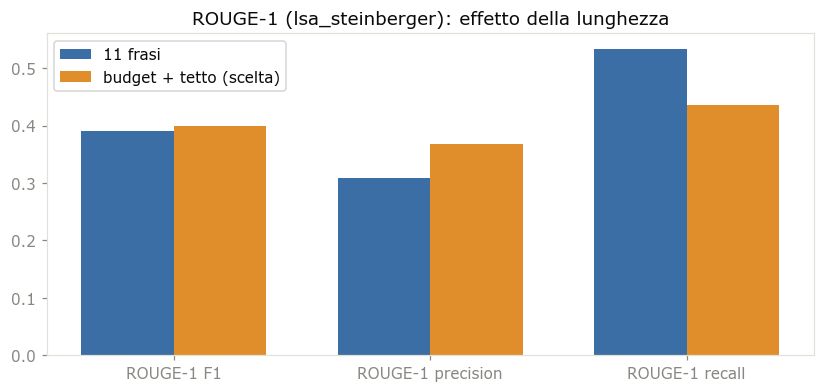

In [18]:
m11 = su.metriche_esempio(valutatore, riassunto_frasi, riferimento)
mbu = su.metriche_esempio(valutatore, riassunto_budget_tetto, riferimento)
m_scelta, m_altra = (m11, mbu) if MODALITA == 'frasi' else (mbu, m11)
assert np.isclose(m_scelta['rouge1_f1'], r1[0])   # coerente con il ROUGE-1 a mano della modalità scelta
et11 = '11 frasi' + (' ◀' if MODALITA == 'frasi' else '')
etbu = 'budget + tetto' + (' ◀' if MODALITA == 'budget' else '')

ordine_col = ['rouge1_f1', 'rouge1_p', 'rouge1_r', 'rouge2_f1', 'rouge2_p', 'rouge2_r',
              'rougeL_f1', 'rougeL_p', 'rougeL_r', 'bleu', 'meteor', 'parole_generate']
tab_metriche = pd.DataFrame({et11: m11, etbu: mbu}).loc[ordine_col]
tab_metriche.index = ['ROUGE-1 F1', 'ROUGE-1 precision', 'ROUGE-1 recall', 'ROUGE-2 F1', 'ROUGE-2 precision', 'ROUGE-2 recall',
                      'ROUGE-L F1', 'ROUGE-L precision', 'ROUGE-L recall', 'BLEU', 'METEOR', 'parole generate']
display(tab_metriche.round(3))

fig, ax = plt.subplots(figsize=(9, 3.8))
chiavi = ['rouge1_f1', 'rouge1_p', 'rouge1_r']
x = np.arange(len(chiavi)); w = .36
ax.bar(x - w / 2, [m11[k] for k in chiavi], w, label=et11.replace(' ◀', ' (scelta)'), color='#3b6ea5')
ax.bar(x + w / 2, [mbu[k] for k in chiavi], w, label=etbu.replace(' ◀', ' (scelta)'), color='#e08e2b')
ax.set_xticks(x); ax.set_xticklabels(['ROUGE-1 F1', 'ROUGE-1 precision', 'ROUGE-1 recall'])
ax.legend(); ax.set_title(f'ROUGE-1 ({VARIANTE}): effetto della lunghezza')
plt.show()

**Cosa abbiamo visto.** Con più parole la **recall** sale (si "pescano" più parole del
riferimento) ma la **precision** scende (molte parole in più non servono): la **F1** compensa i
due effetti ed è la metrica più onesta quando le lunghezze sono diverse. A parità di lunghezza
(budget), la differenza tra metodi riflette davvero la qualità della *selezione dei contenuti*.

## 12. Interpretazione dei risultati
Il commento seguente legge i numeri **di questa riga** (si aggiorna se cambi `ROW_ID`, `VARIANTE` o `MODALITA`).

In [19]:
nome_altra = 'budget + tetto' if MODALITA == 'frasi' else '11 frasi'
dr, db = m_altra['rouge1_r'] - m_scelta['rouge1_r'], m_altra['rouge1_p'] - m_scelta['rouge1_p']
testo = f"""
**Riga {ROW_ID} — {VARIANTE} (K = {K} concetti) — MODALITA `'{MODALITA}'`.**

- La SVD tiene {K} concetti su {r}, che conservano il {energia[:K].sum():.0%} dell'energia della matrice; il primo
  da solo ne porta il {energia[0]:.0%}.
- Il riassunto ha {m_scelta['parole_generate']} parole contro le {len(riferimento.split())} del riferimento
  ({m_scelta['parole_generate'] / len(riferimento.split()):.1f}×): ROUGE-1 recall = **{m_scelta['rouge1_r']:.3f}**,
  precision = **{m_scelta['rouge1_p']:.3f}**, F1 = **{m_scelta['rouge1_f1']:.3f}**.
- Per confronto, con la modalità *{nome_altra}* ({m_altra['parole_generate']} parole) la recall {'sale' if dr > 0 else 'scende'} a
  **{m_altra['rouge1_r']:.3f}** (Δ = {dr:+.3f}) e la precision {'sale' if db > 0 else 'scende'} a **{m_altra['rouge1_p']:.3f}**
  (Δ = {db:+.3f}): F1 = **{m_altra['rouge1_f1']:.3f}**.
- ROUGE-2 F1 = {m_scelta['rouge2_f1']:.3f} (modalità scelta): molto più bassa di ROUGE-1, perché le sequenze di **due parole**
  consecutive in comune col riferimento *astratto* sono rare — è tipico dei metodi estrattivi.
"""
display(Markdown(testo))


**Riga 50492 — lsa_steinberger (K = 11 concetti) — MODALITA `'budget'`.**

- La SVD tiene 11 concetti su 19, che conservano il 68% dell'energia della matrice; il primo
  da solo ne porta il 12%.
- Il riassunto ha 185 parole contro le 168 del riferimento
  (1.1×): ROUGE-1 recall = **0.437**,
  precision = **0.369**, F1 = **0.400**.
- Per confronto, con la modalità *11 frasi* (312 parole) la recall sale a
  **0.534** (Δ = +0.097) e la precision scende a **0.309**
  (Δ = -0.060): F1 = **0.391**.
- ROUGE-2 F1 = 0.163 (modalità scelta): molto più bassa di ROUGE-1, perché le sequenze di **due parole**
  consecutive in comune col riferimento *astratto* sono rare — è tipico dei metodi estrattivi.


### Cosa portarsi a casa
1. **LSA è un ordinamento di frasi in uno spazio di concetti.** La SVD comprime la matrice frase × termine
   in pochi concetti pesati per σ; la salienza `‖z‖` premia le frasi che parlano molto dei concetti
   importanti. Lunghezza, ordine di emissione e coerenza del testo finale sono scelte esterne.
2. **Su un singolo cluster lo spettro è piatto.** Con ~20 frasi solo uno o due concetti sono temi davvero
   condivisi; gli altri sono frasi isolate con σ ≈ 1, che la salienza premia. LSA tende così a scegliere frasi
   corte e periferiche: è la sua debolezza principale su Multi-News.
3. **Nessun modello addestrato.** Solo algebra lineare sulle frasi del cluster: semplice, scalabile e
   indipendente dalla lingua (a parte le stop-word) — i pro citati a lezione. Il contro: lavora solo su
   relazioni tra **parole singole** e con ~20 frasi ha poca statistica per scoprire vere "sinonimie".
4. **La deflazione è l'anti-ridondanza di LSA.** Togliere dallo spazio la direzione già coperta fa
   l'equivalente della penalità di MMR (notebook 11), ma in modo geometrico e senza parametri da tarare.
   Vincolo: dopo `K` scelte lo spazio è esaurito, quindi serve `K ≥ N_SENTENCES`.
5. **Nel benchmark la deflazione paga.** Sulle 5.588 righe di test, ROUGE-1 F1 `lsa` 0,351 contro
   `lsa_steinberger` **0,376** a 11 frasi (~249 vs ~257 parole: lunghezze quasi uguali, quindi non è un
   effetto di lunghezza — la recall sale da 0,357 a 0,419); a budget 0,350 contro **0,369**. È il miglior
   risultato tra i cinque estrattivi dei notebook 15-17.
6. **La lunghezza è un confondente, qui piccolo.** Passando a budget (~215 parole) F1 cala di 0,001 per `lsa`
   e di 0,007 per `lsa_steinberger`: a differenza di LDA (che perde tutto il suo vantaggio), LSA non doveva
   la sua posizione alla lunghezza.
7. **Il tetto delle metriche estrattive.** Il riferimento è astratto; le frasi estratte non lo riprodurranno mai.

### Esercizi proposti
- Cambia `ROW_ID` (es. 50501, 50523) e osserva come cambiano scree plot, concetti e selezione.
- Passa `VARIANTE` da `'lsa_steinberger'` a `'lsa'` e rileggi le sezioni 8-12: in modalità `'budget'` cambia qualcosa?
  E in modalità `'frasi'`?
- Con `MODALITA = 'frasi'` prova `K_LATENTE = 1` e `3`: le frasi scelte diventano più lunghe? Quante ne sceglie
  la deflazione prima del ripiego? Le metriche migliorano o peggiorano?
- Nella sezione 6, quante coppie senza parole in comune diventano "vicine" con `K_LATENTE = 3`? E con `K_LATENTE = 15`?

### Limiti di questa implementazione
Due scelte limitano LSA così com'è nel benchmark, **indipendentemente dalla variante**.

1. **Vettorizzazione TF-IDF.** Con cluster piccoli (~20 frasi) la matrice è sparsa e ha poche co-occorrenze: la «sinonimia» di LSA resta modesta (sezione 6) e le frasi isolate diventano concetti da σ = 1 premiati dalla salienza (sezioni 4-5). Una vettorizzazione **densa** (ad esempio embedding SBERT) darebbe vettori semantici anche con poche frasi, senza frasi perfettamente isolate. Non è una sostituzione a costo zero: la SVD su embedding densi equivale a una compressione tipo PCA, si perde la lettura dei concetti come insiemi di parole e cambia il senso di σ. **Non è stata provata nel progetto**; SBERT è usato in 11 (BERT) e 16, ma con metodi diversi.
2. **Scelta di `K_LATENTE`.** Vale 11 perché è la mediana delle frasi dei riassunti di riferimento: è il numero di frasi da estrarre, non una dimensione scelta per l'adeguatezza dello spazio latente. Una taratura corretta sceglierebbe `K` su un insieme di validazione, probabilmente per variante: un'esplorazione preliminare fuori dal benchmark (circa 400 righe di test, senza intervalli di confidenza, quindi solo indicativa) suggerisce che `lsa` preferisca un `K` piccolo e `lsa_steinberger` un `K` alto. Il `K = 11` del benchmark favorisce quindi la seconda. Gli esercizi sotto permettono di vedere l'effetto su questa riga.

I numeri del benchmark citati sopra restano quelli pubblicati.

## 13. (Extra) `lsa` e `lsa_steinberger` a confronto sulla stessa riga
Le due varianti del benchmark differiscono **solo** per la regola di selezione: segmentazione, matrice
TF-IDF e SVD sono identiche. Calcoliamo qui entrambe sulla stessa riga, con lo stesso criterio di
lunghezza (`MODALITA`), e confrontiamo frasi scelte, ridondanza del set e metriche.

MODALITA 'budget' | frasi scelte da entrambe: [2, 3, 4, 6, 7, 9, 12, 13, 15] | solo lsa: [] | solo lsa_steinberger: []


,lsa,lsa_steinberger
rouge1_f1,0.400,0.400
rouge1_p,0.369,0.369
rouge1_r,0.437,0.437
rouge2_f1,0.163,0.163
rougeL_f1,0.180,0.180
meteor,0.441,0.441
parole_generate,185.000,185.000
ridondanza media del set,0.006,0.006


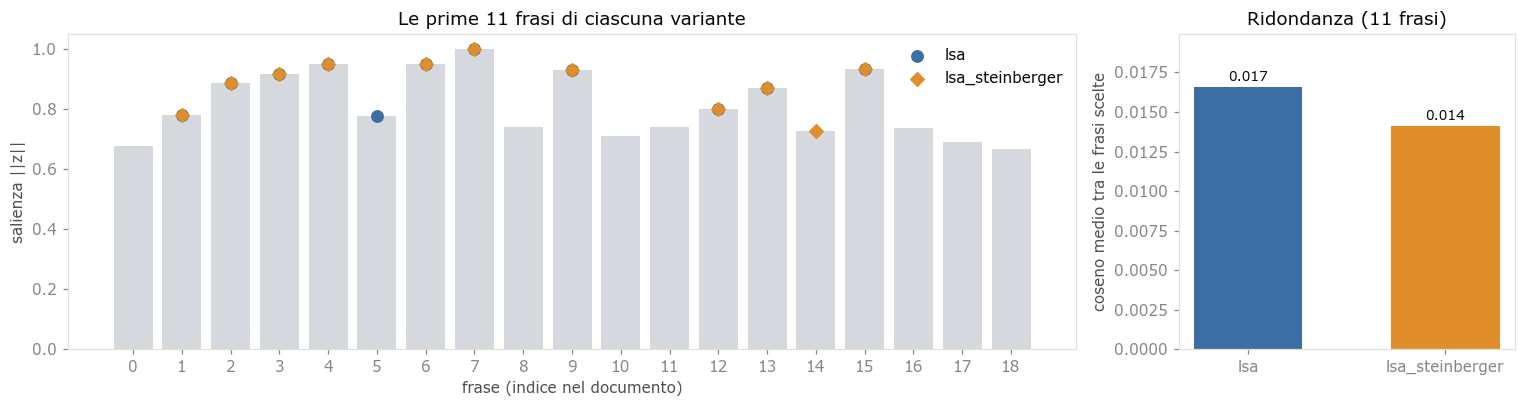

In [20]:
risultati = {}
for var in ('lsa', 'lsa_steinberger'):
    ord_v = ORDINI[var]
    sel = (ord_v[:N_SENTENCES] if N > N_SENTENCES else list(range(N))) if MODALITA == 'frasi' else su.seleziona_per_budget(frasi, ord_v, budget)
    testo_ = ' '.join(frasi[i] for i in sorted(sel))
    if MODALITA == 'budget':
        testo_ = su.tronca_parole(testo_, tetto)
    assert testo_ == (make_genera(var)(documento) if MODALITA == 'frasi' else su.tronca_parole(make_genera(var)(documento, budget=budget), tetto))
    risultati[var] = {'sel': list(sel), 'testo': testo_, 'metriche': su.metriche_esempio(valutatore, testo_, riferimento)}

a, b = risultati['lsa'], risultati['lsa_steinberger']
comuni = sorted(set(a['sel']) & set(b['sel']))
print(f"MODALITA '{MODALITA}' | frasi scelte da entrambe: {comuni} | solo lsa: {sorted(set(a['sel']) - set(b['sel']))} "
      f"| solo lsa_steinberger: {sorted(set(b['sel']) - set(a['sel']))}")

chiavi = ('rouge1_f1', 'rouge1_p', 'rouge1_r', 'rouge2_f1', 'rougeL_f1', 'meteor', 'parole_generate')
tab = pd.DataFrame({var: {k: risultati[var]['metriche'][k] for k in chiavi} for var in risultati}).round(3)
tab.loc['ridondanza media del set'] = [round(ridondanza_media(risultati[v]['sel']), 3) for v in risultati]
display(tab)

# confronto anche a 11 frasi, dove le due varianti hanno più spazio per divergere
sel11 = {v: ORDINI[v][:N_SENTENCES] for v in ORDINI}
fig, assi = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={'width_ratios': [3, 1]})
assi[0].bar(range(N), salienza, color='#d5d8dc')
assi[0].scatter(sel11['lsa'], salienza[sel11['lsa']], s=55, color='#3b6ea5', label='lsa', zorder=3)
assi[0].scatter(sel11['lsa_steinberger'], salienza[sel11['lsa_steinberger']], s=40, marker='D', color='#e08e2b',
                label='lsa_steinberger', zorder=4)
assi[0].set_xticks(range(N)); assi[0].set_xlabel('frase (indice nel documento)'); assi[0].set_ylabel('salienza ||z||')
assi[0].set_title(f'Le prime {N_SENTENCES} frasi di ciascuna variante'); assi[0].legend(frameon=False)
valori = [ridondanza_media(sel11[v]) for v in ('lsa', 'lsa_steinberger')]
assi[1].bar([0, 1], valori, color=['#3b6ea5', '#e08e2b'], width=.55)
for i_, v in enumerate(valori):
    assi[1].annotate(f'{v:.3f}', (i_, v), xytext=(0, 4), textcoords='offset points', ha='center', fontsize=9)
assi[1].set_xticks([0, 1]); assi[1].set_xticklabels(['lsa', 'lsa_steinberger'])
assi[1].set_ylabel('coseno medio tra le frasi scelte'); assi[1].set_title('Ridondanza (11 frasi)'); assi[1].margins(y=.2)
plt.tight_layout(); plt.show()

**Cosa abbiamo visto.** Su una riga corta come la 50492 le due varianti coincidono quasi del tutto: le prime
9 scelte sono identiche (le frasi isolate sono già ortogonali tra loro) e a budget il riassunto è lo stesso. La differenza emerge quando l'ordine è lungo e il cluster ripete lo stesso fatto in
più articoli. Su una sola riga la ridondanza lessicale del set può persino non scendere: la deflazione
toglie ridondanza **nello spazio dei concetti troncato**, non nel coseno TF-IDF. Nel benchmark
(5.588 righe) la differenza è però netta e sistematica a favore di `lsa_steinberger`: ROUGE-1 F1 0,376 vs
0,351 a 11 frasi, 0,369 vs 0,350 a budget.